# 08 - Explainability and cross-dataset analysis

SHAP values explain *model behaviour*; they are not causal effects.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
M = ROOT / 'results' / 'metrics'; F = ROOT / 'results' / 'figures'; P = ROOT / 'data' / 'processed'
sh = json.load(open(M/'shap_summary.json'))
json.dumps(sh['qol_stress'], indent=1)[:3000]

'{\n "ECG+EDA+HR | early | logreg": {\n  "output_scale": "log-odds",\n  "rank_stability_mean_pairwise_spearman": 0.7392857142857141,\n  "modality_share": {\n   "ECG": 0.2763,\n   "EDA": 0.3936,\n   "HR": 0.3301\n  },\n  "top5": [\n   {\n    "feature": "fb_hr_slope",\n    "mean_abs_shap": 0.053,\n    "mean_shap": -0.0105\n   },\n   {\n    "feature": "ecg_hr_range",\n    "mean_abs_shap": 0.0521,\n    "mean_shap": 0.0003\n   },\n   {\n    "feature": "eda_scl_range",\n    "mean_abs_shap": 0.0478,\n    "mean_shap": -0.0007\n   },\n   {\n    "feature": "eda_scl_std",\n    "mean_abs_shap": 0.0438,\n    "mean_shap": -0.003\n   },\n   {\n    "feature": "ecg_sdnn",\n    "mean_abs_shap": 0.04,\n    "mean_shap": -0.0002\n   }\n  ],\n  "individual_examples": {\n   "confident_stress": {\n    "pid": "Q13",\n    "phase": "stress",\n    "prob_stress": 0.7275022914999895\n   },\n   "confident_relax": {\n    "pid": "Q05",\n    "phase": "relax",\n    "prob_stress": 0.36236255525676997\n   },\n   "misclass

**shap_bar_ecg_eda_hr_early_logreg**

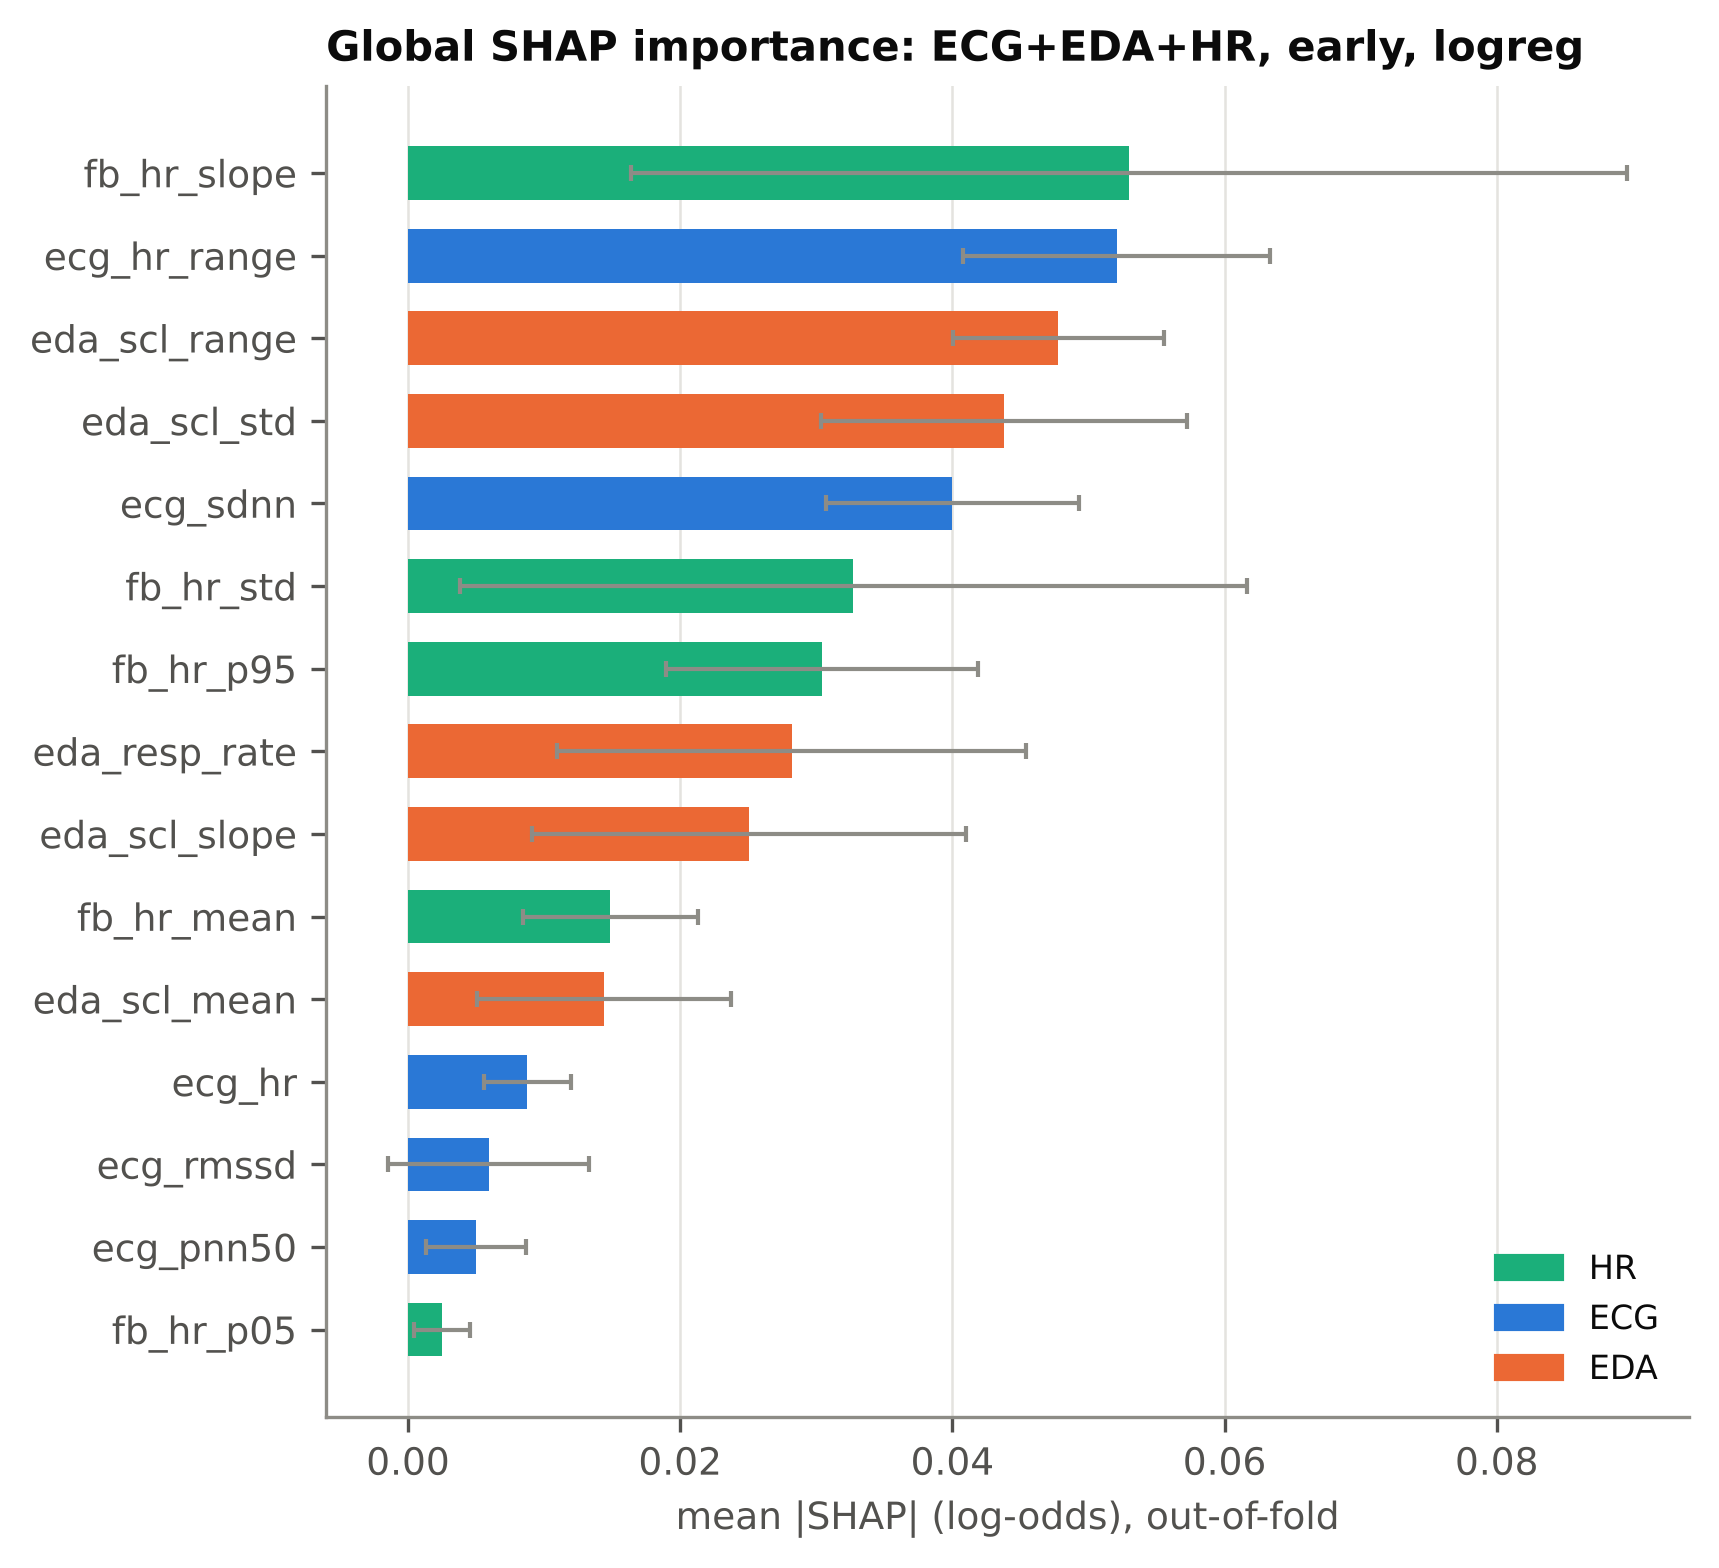

**shap_bar_ecg_eda_hr_early_xgboost**

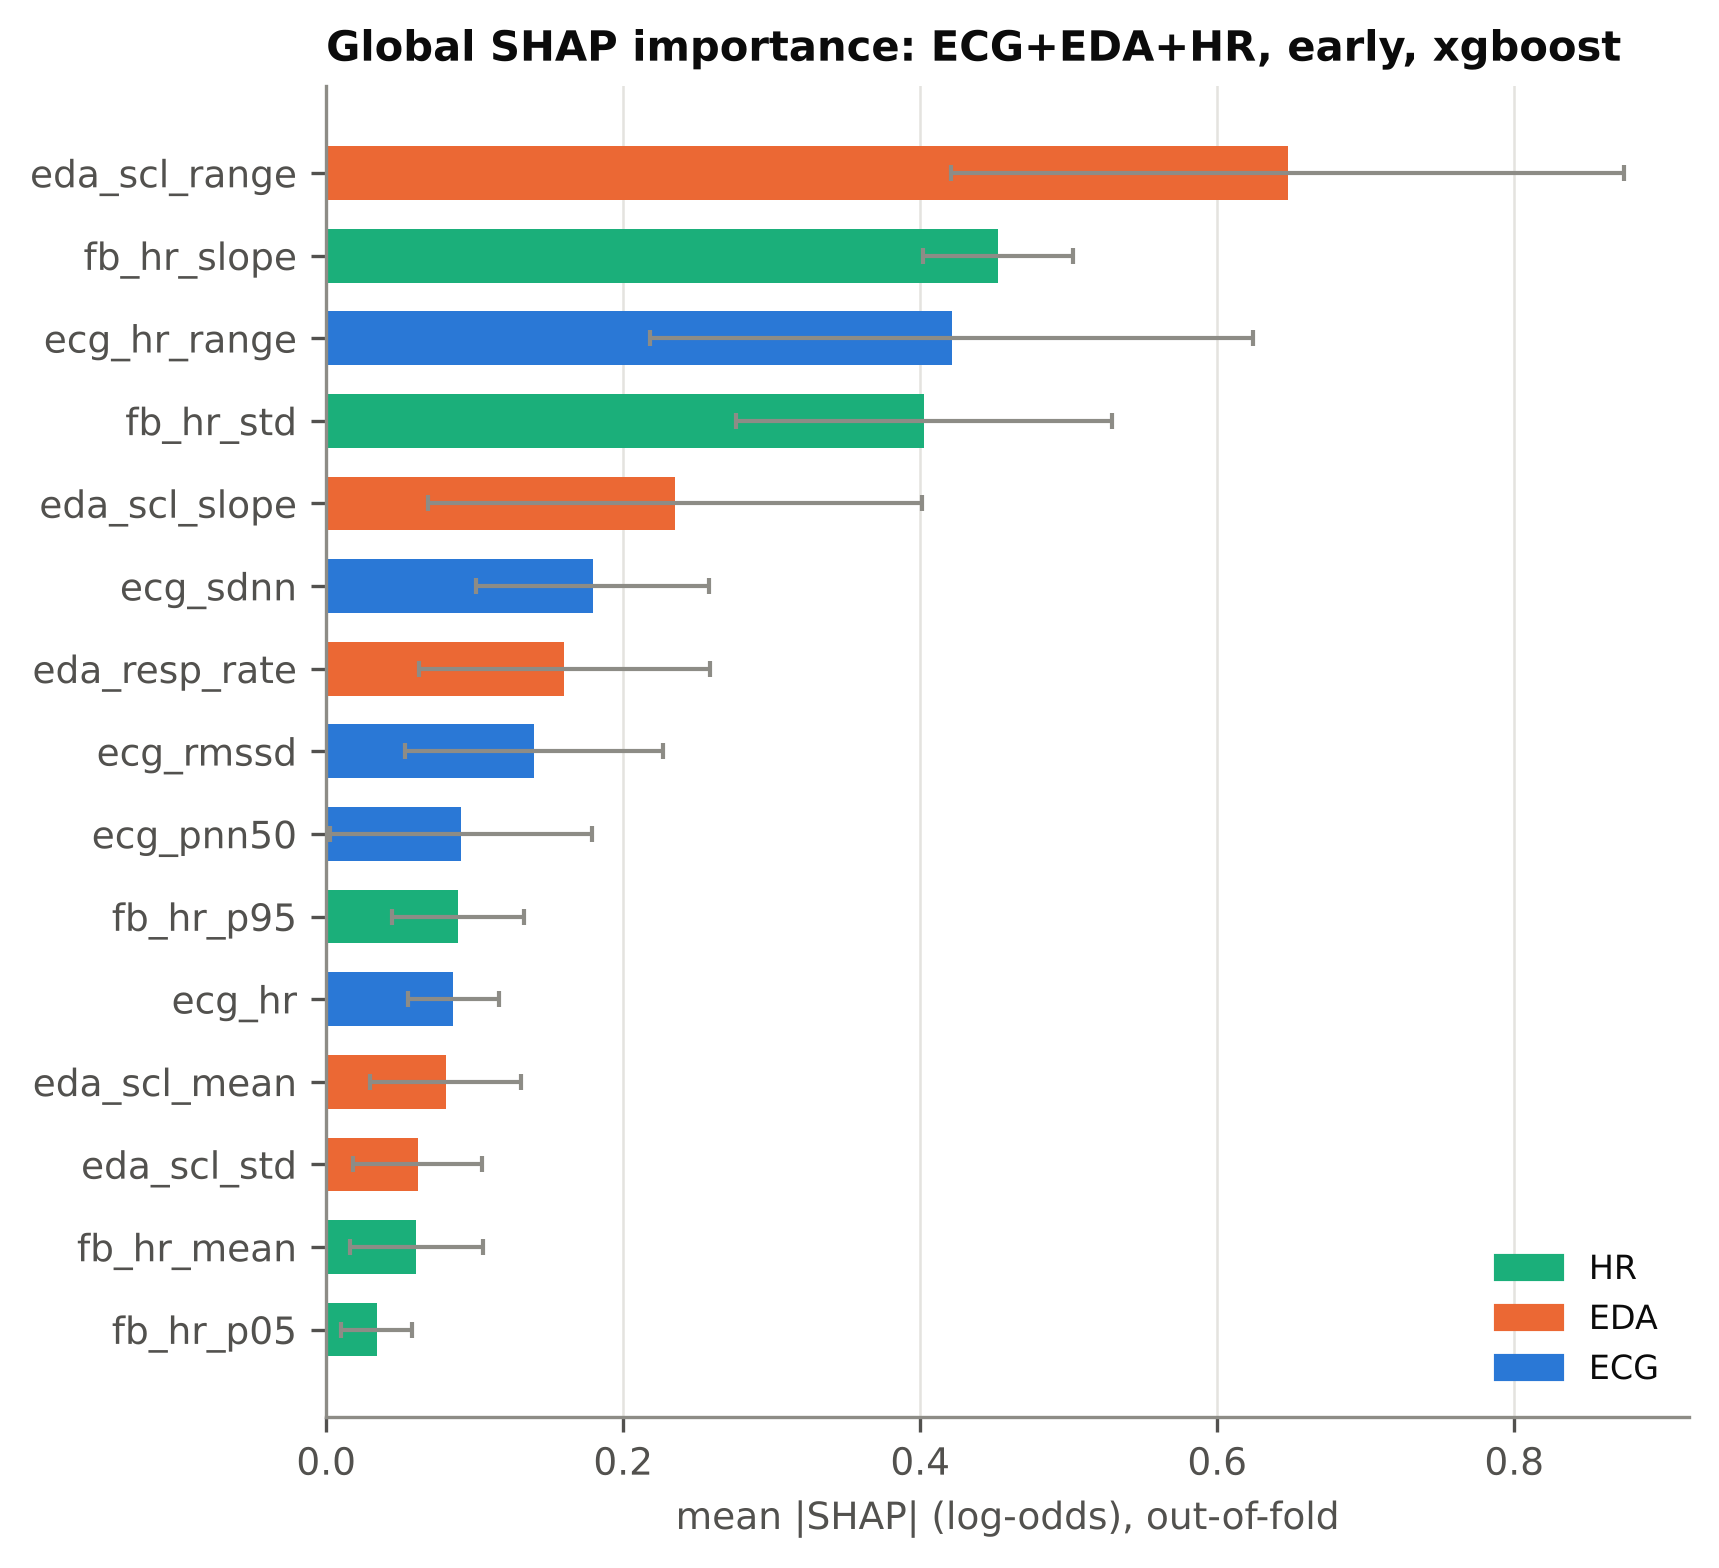

**shap_bar_eda_single_random_forest**

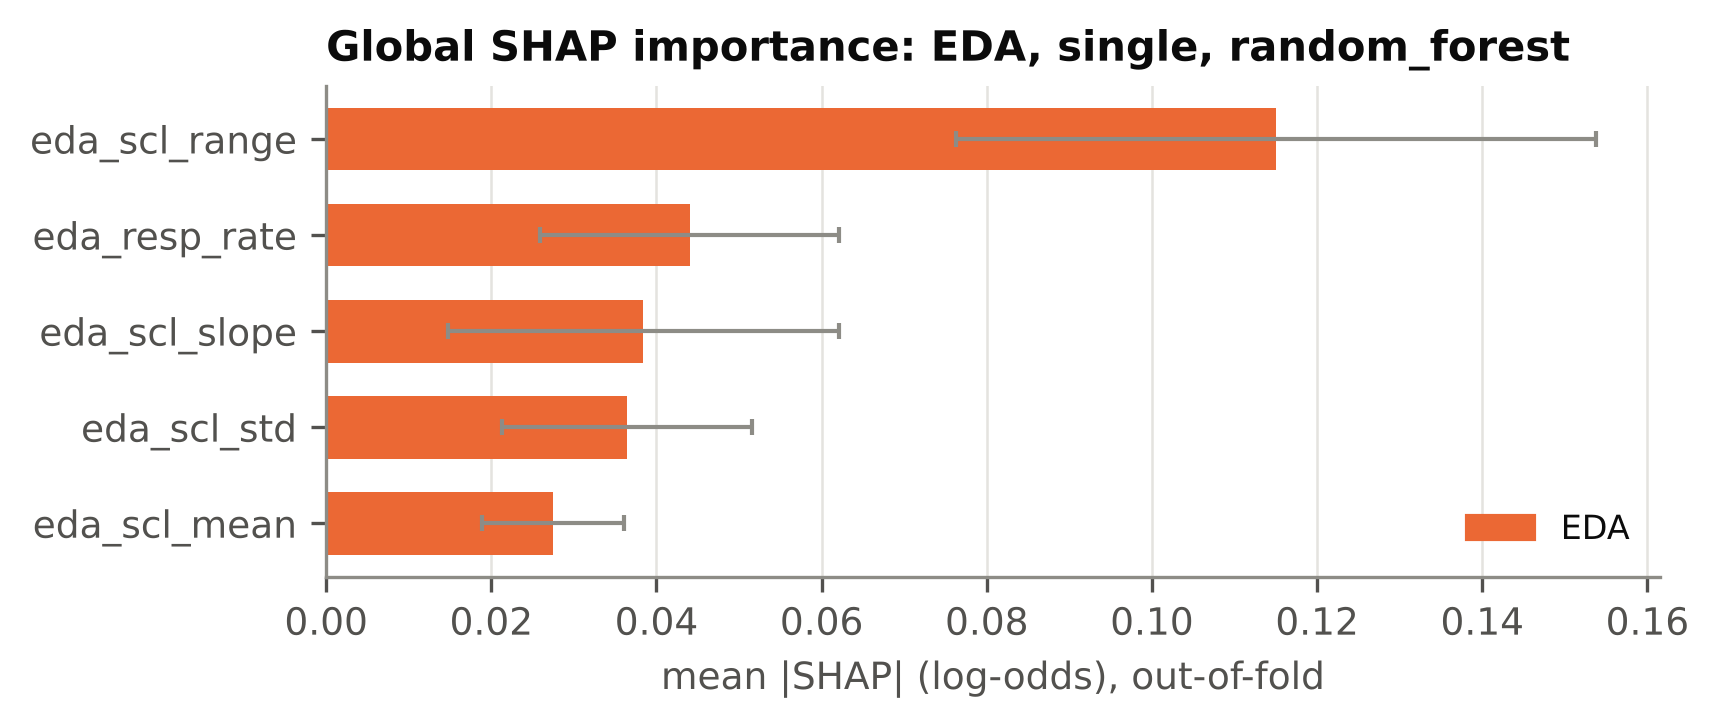

**shap_bar_mmash_sleep_efficiency**

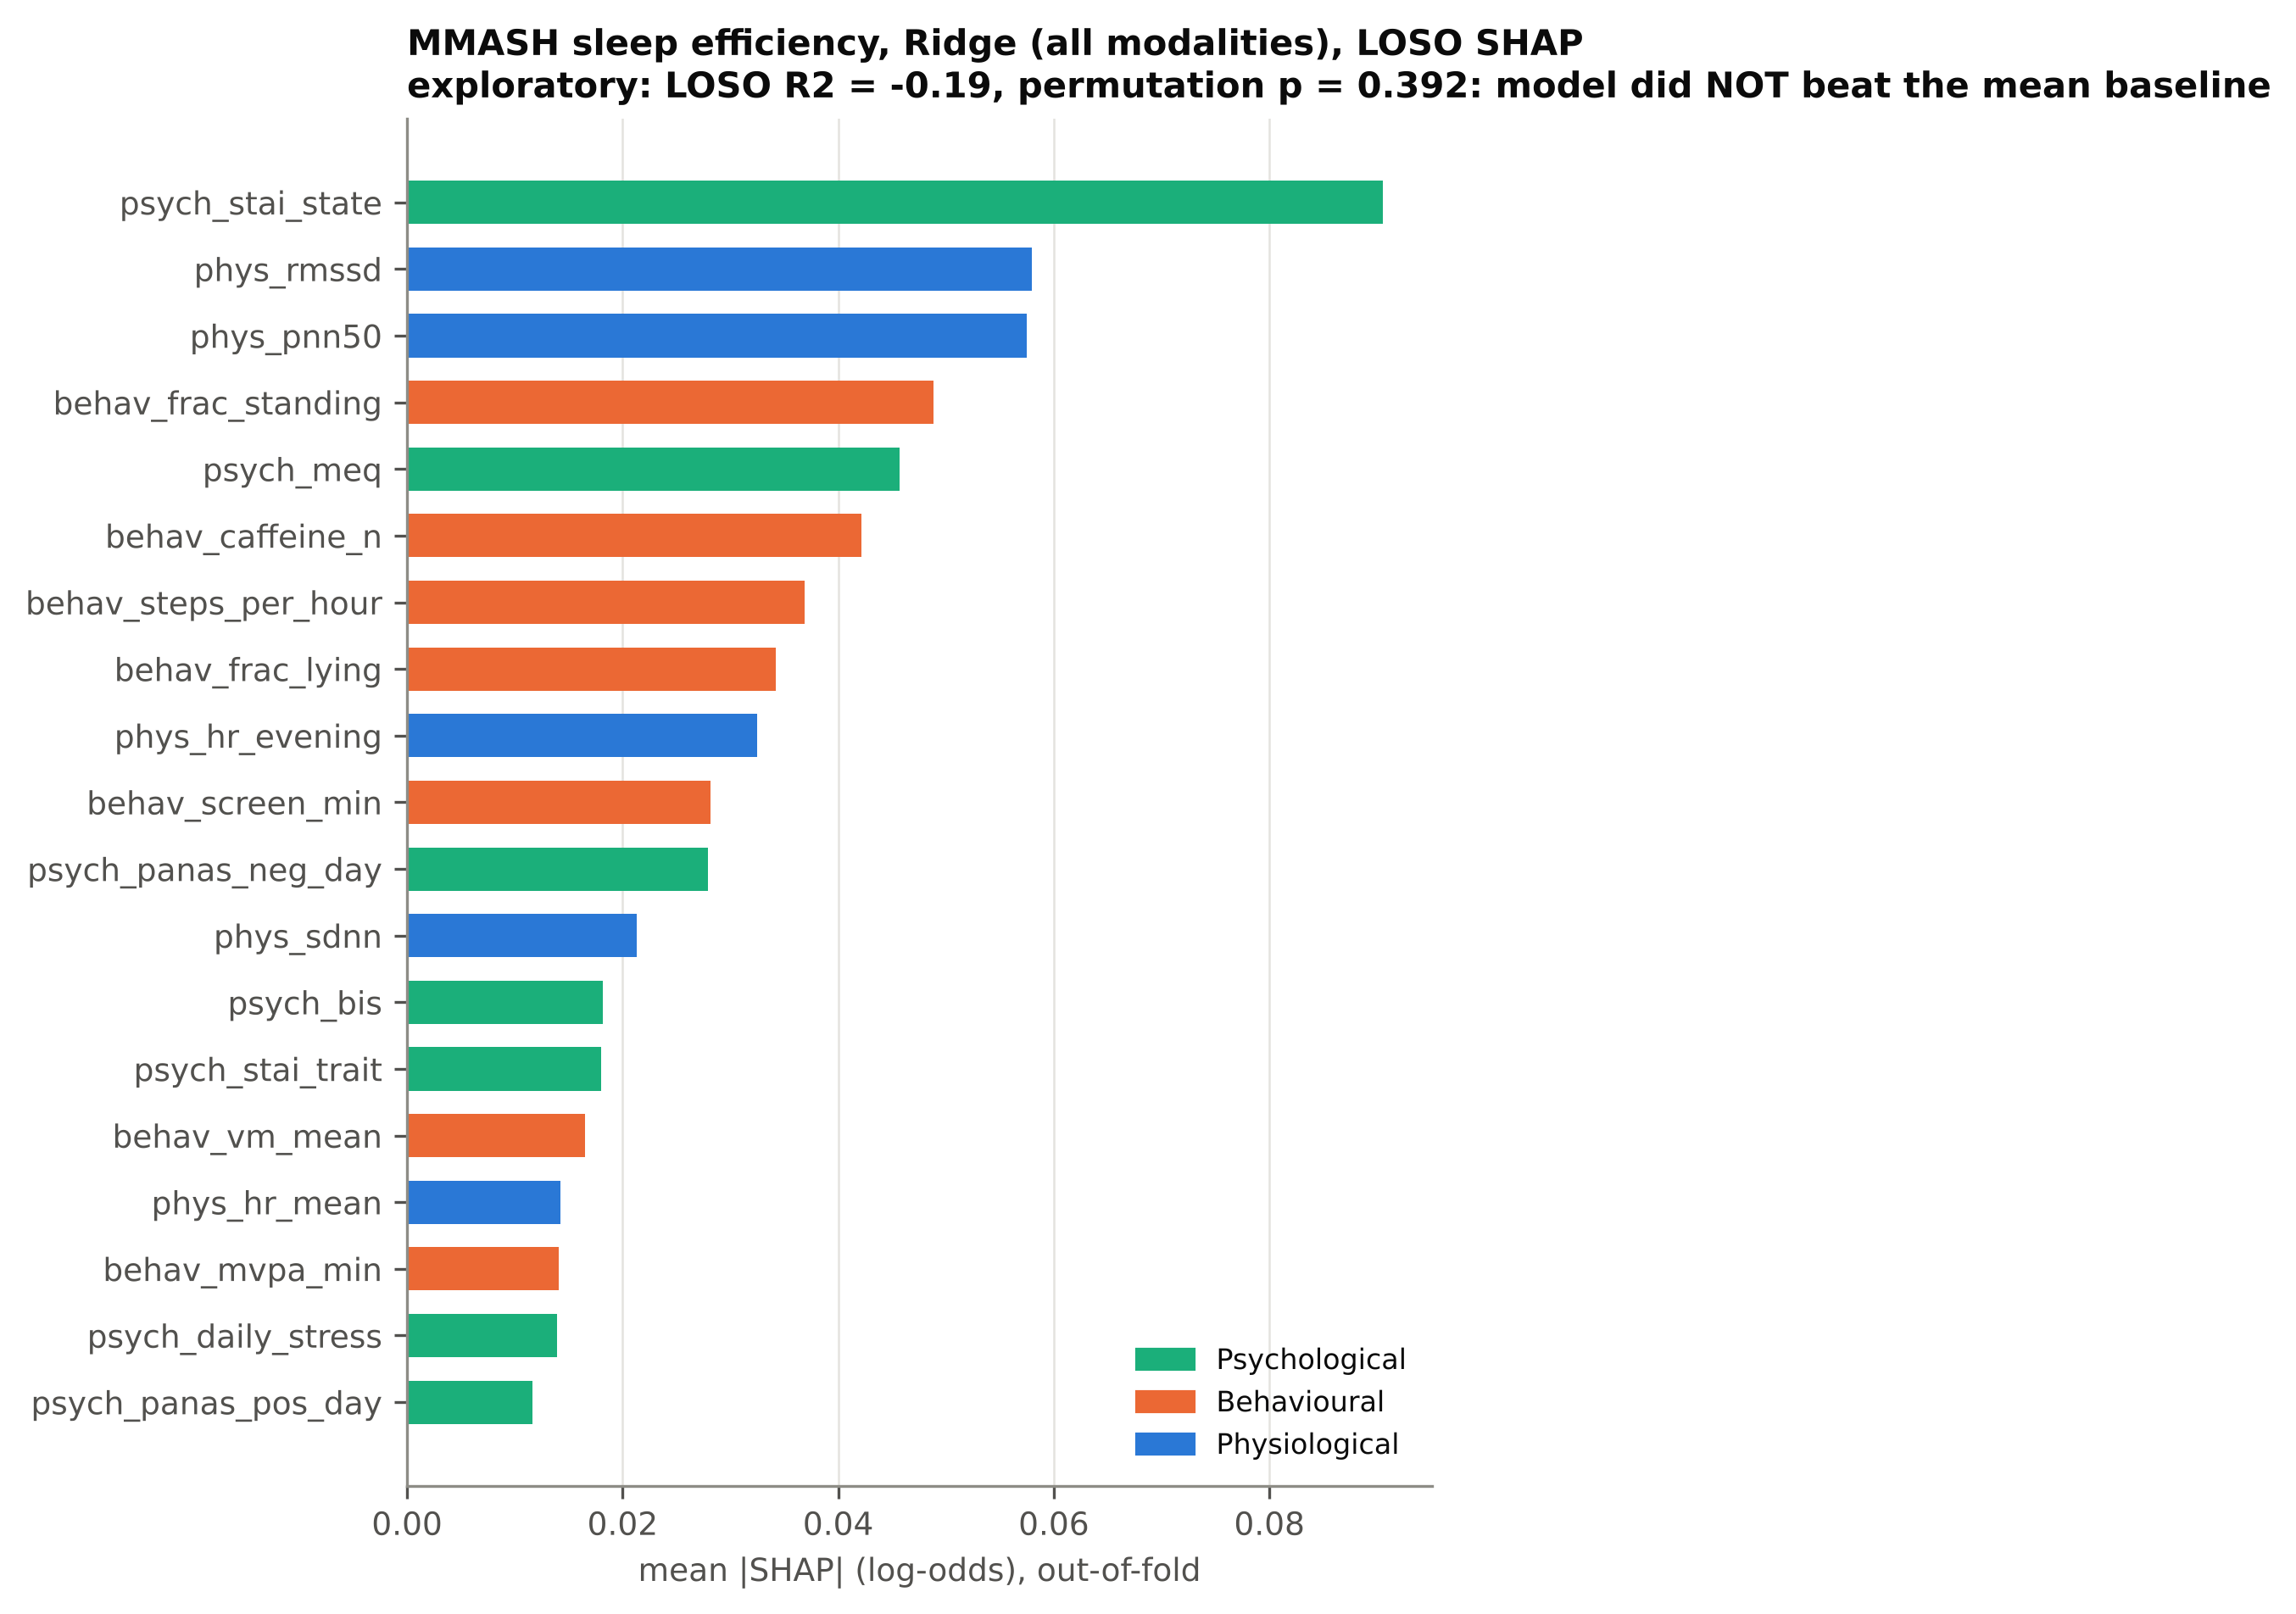

In [2]:
for p in sorted(F.glob('shap_bar_*.png')): display(Markdown(f'**{p.stem}**')); display(Image(p, width=560))

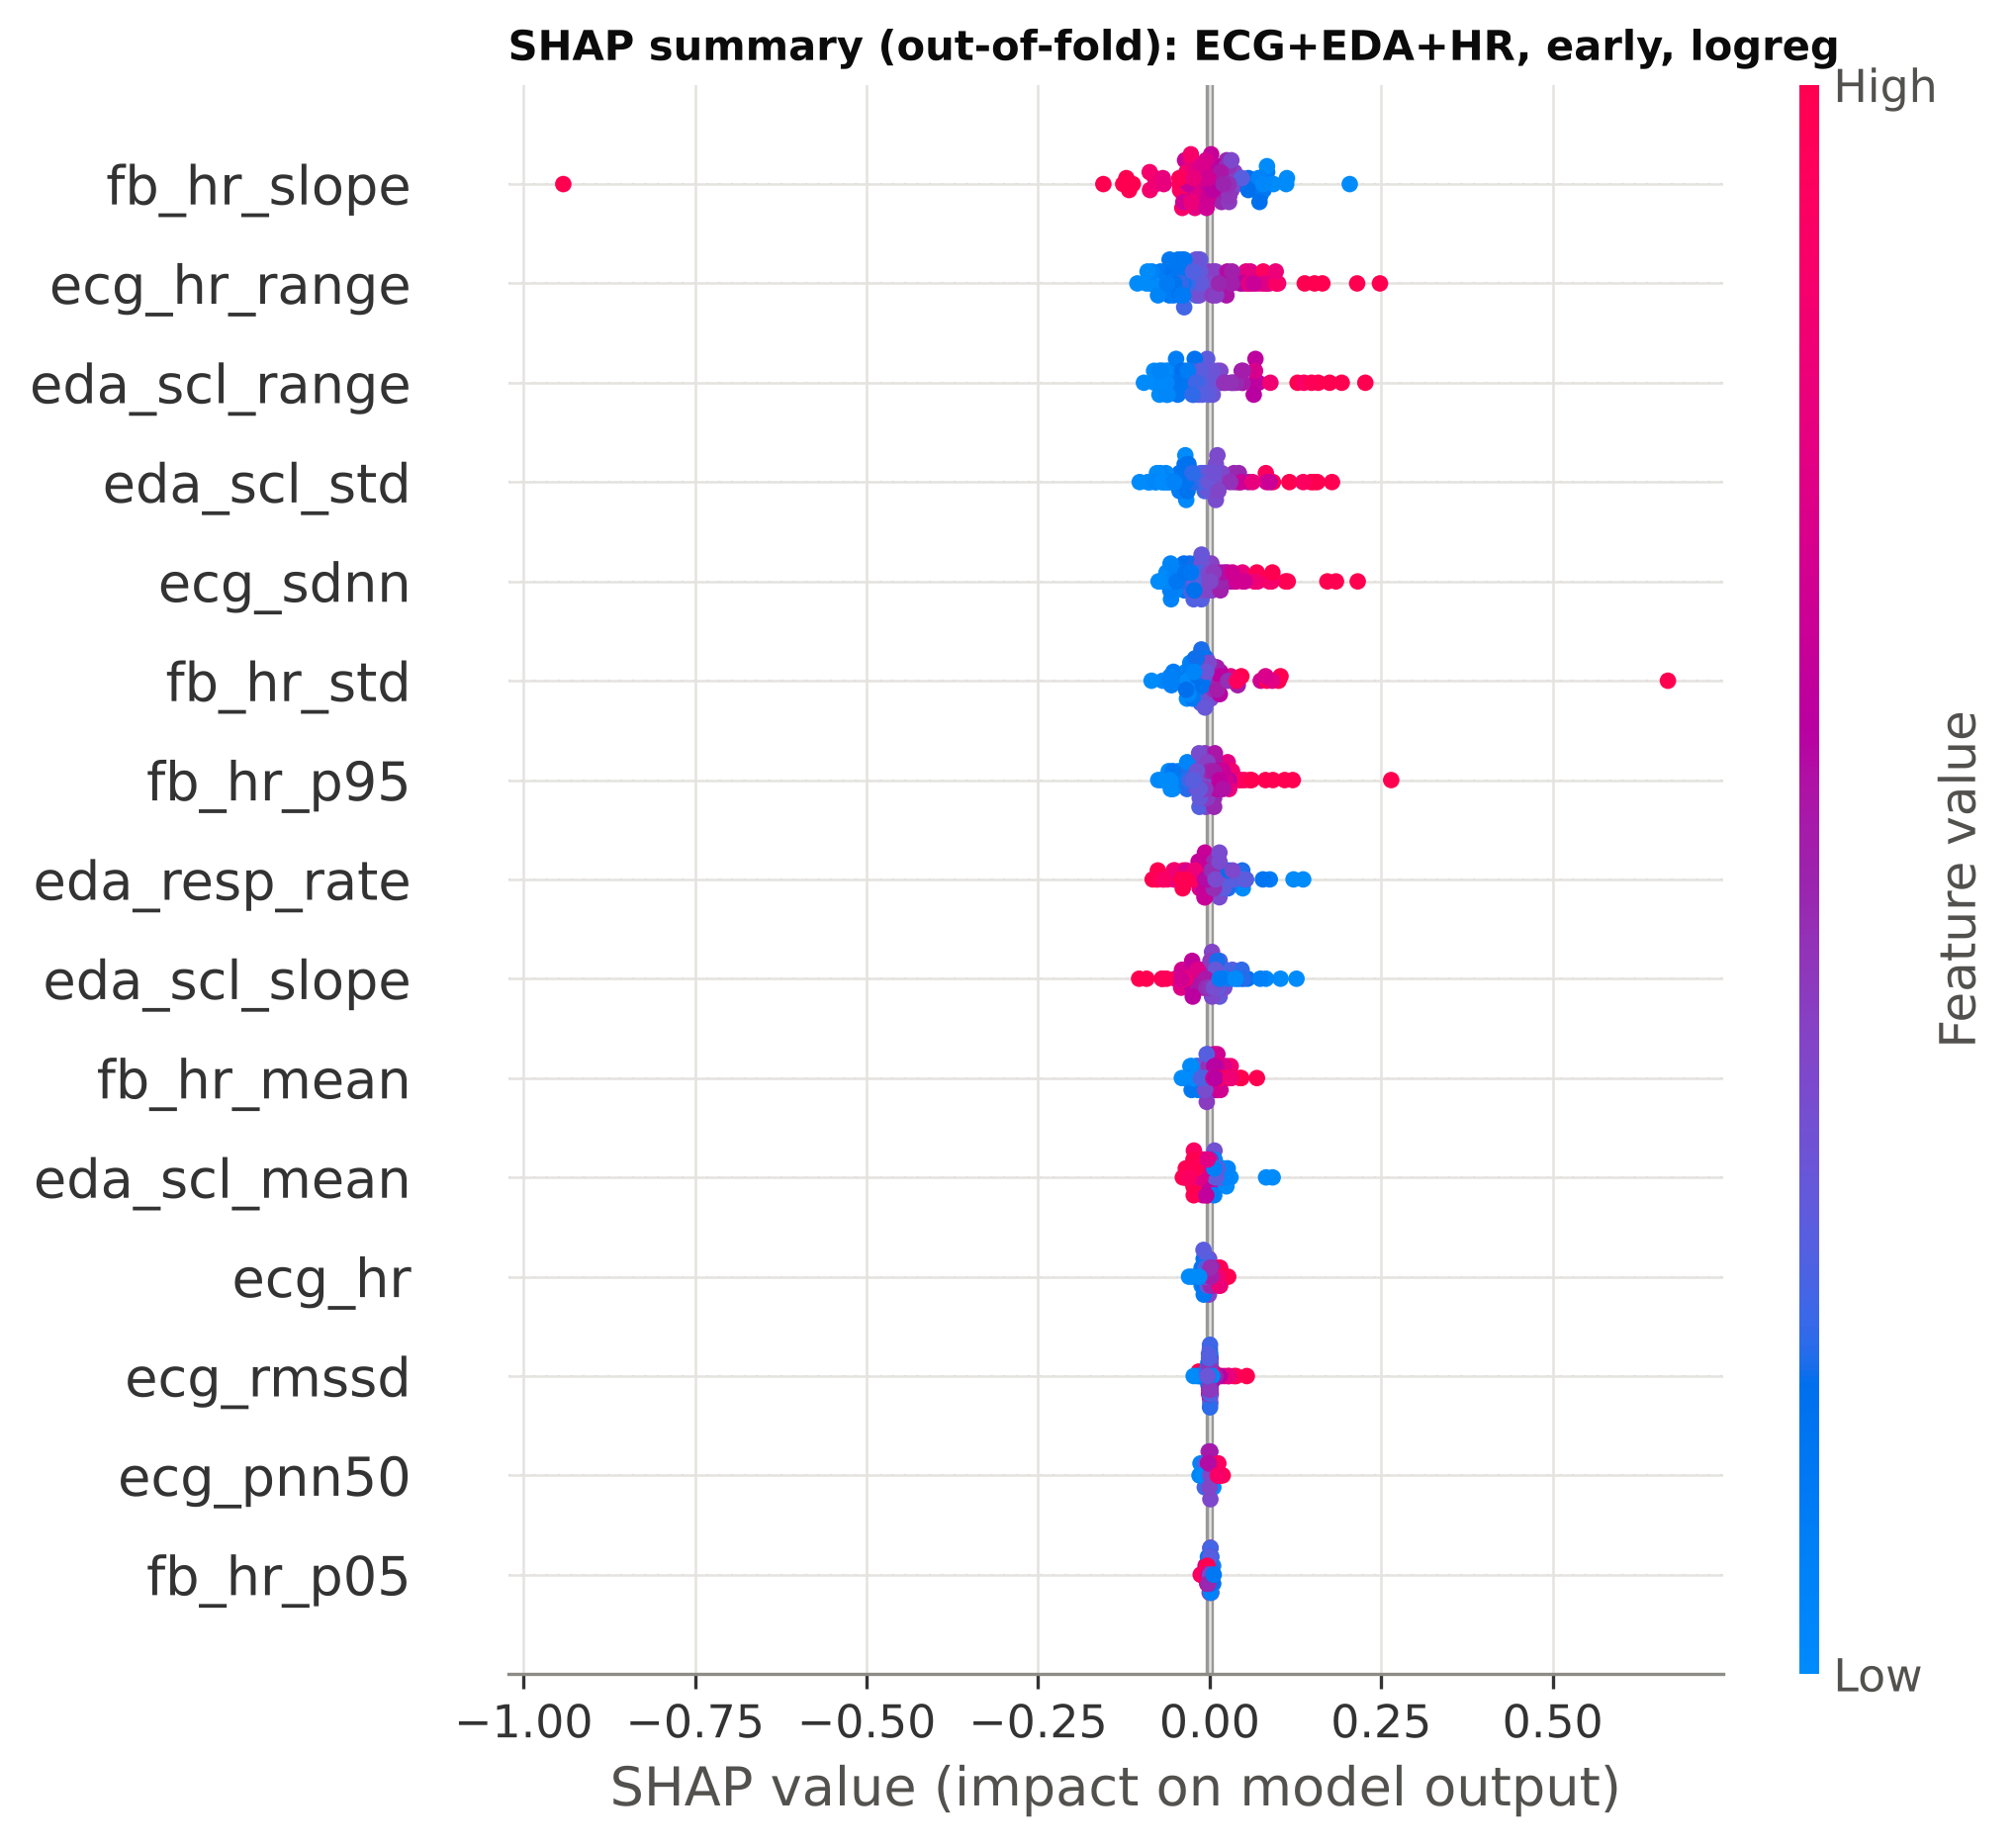

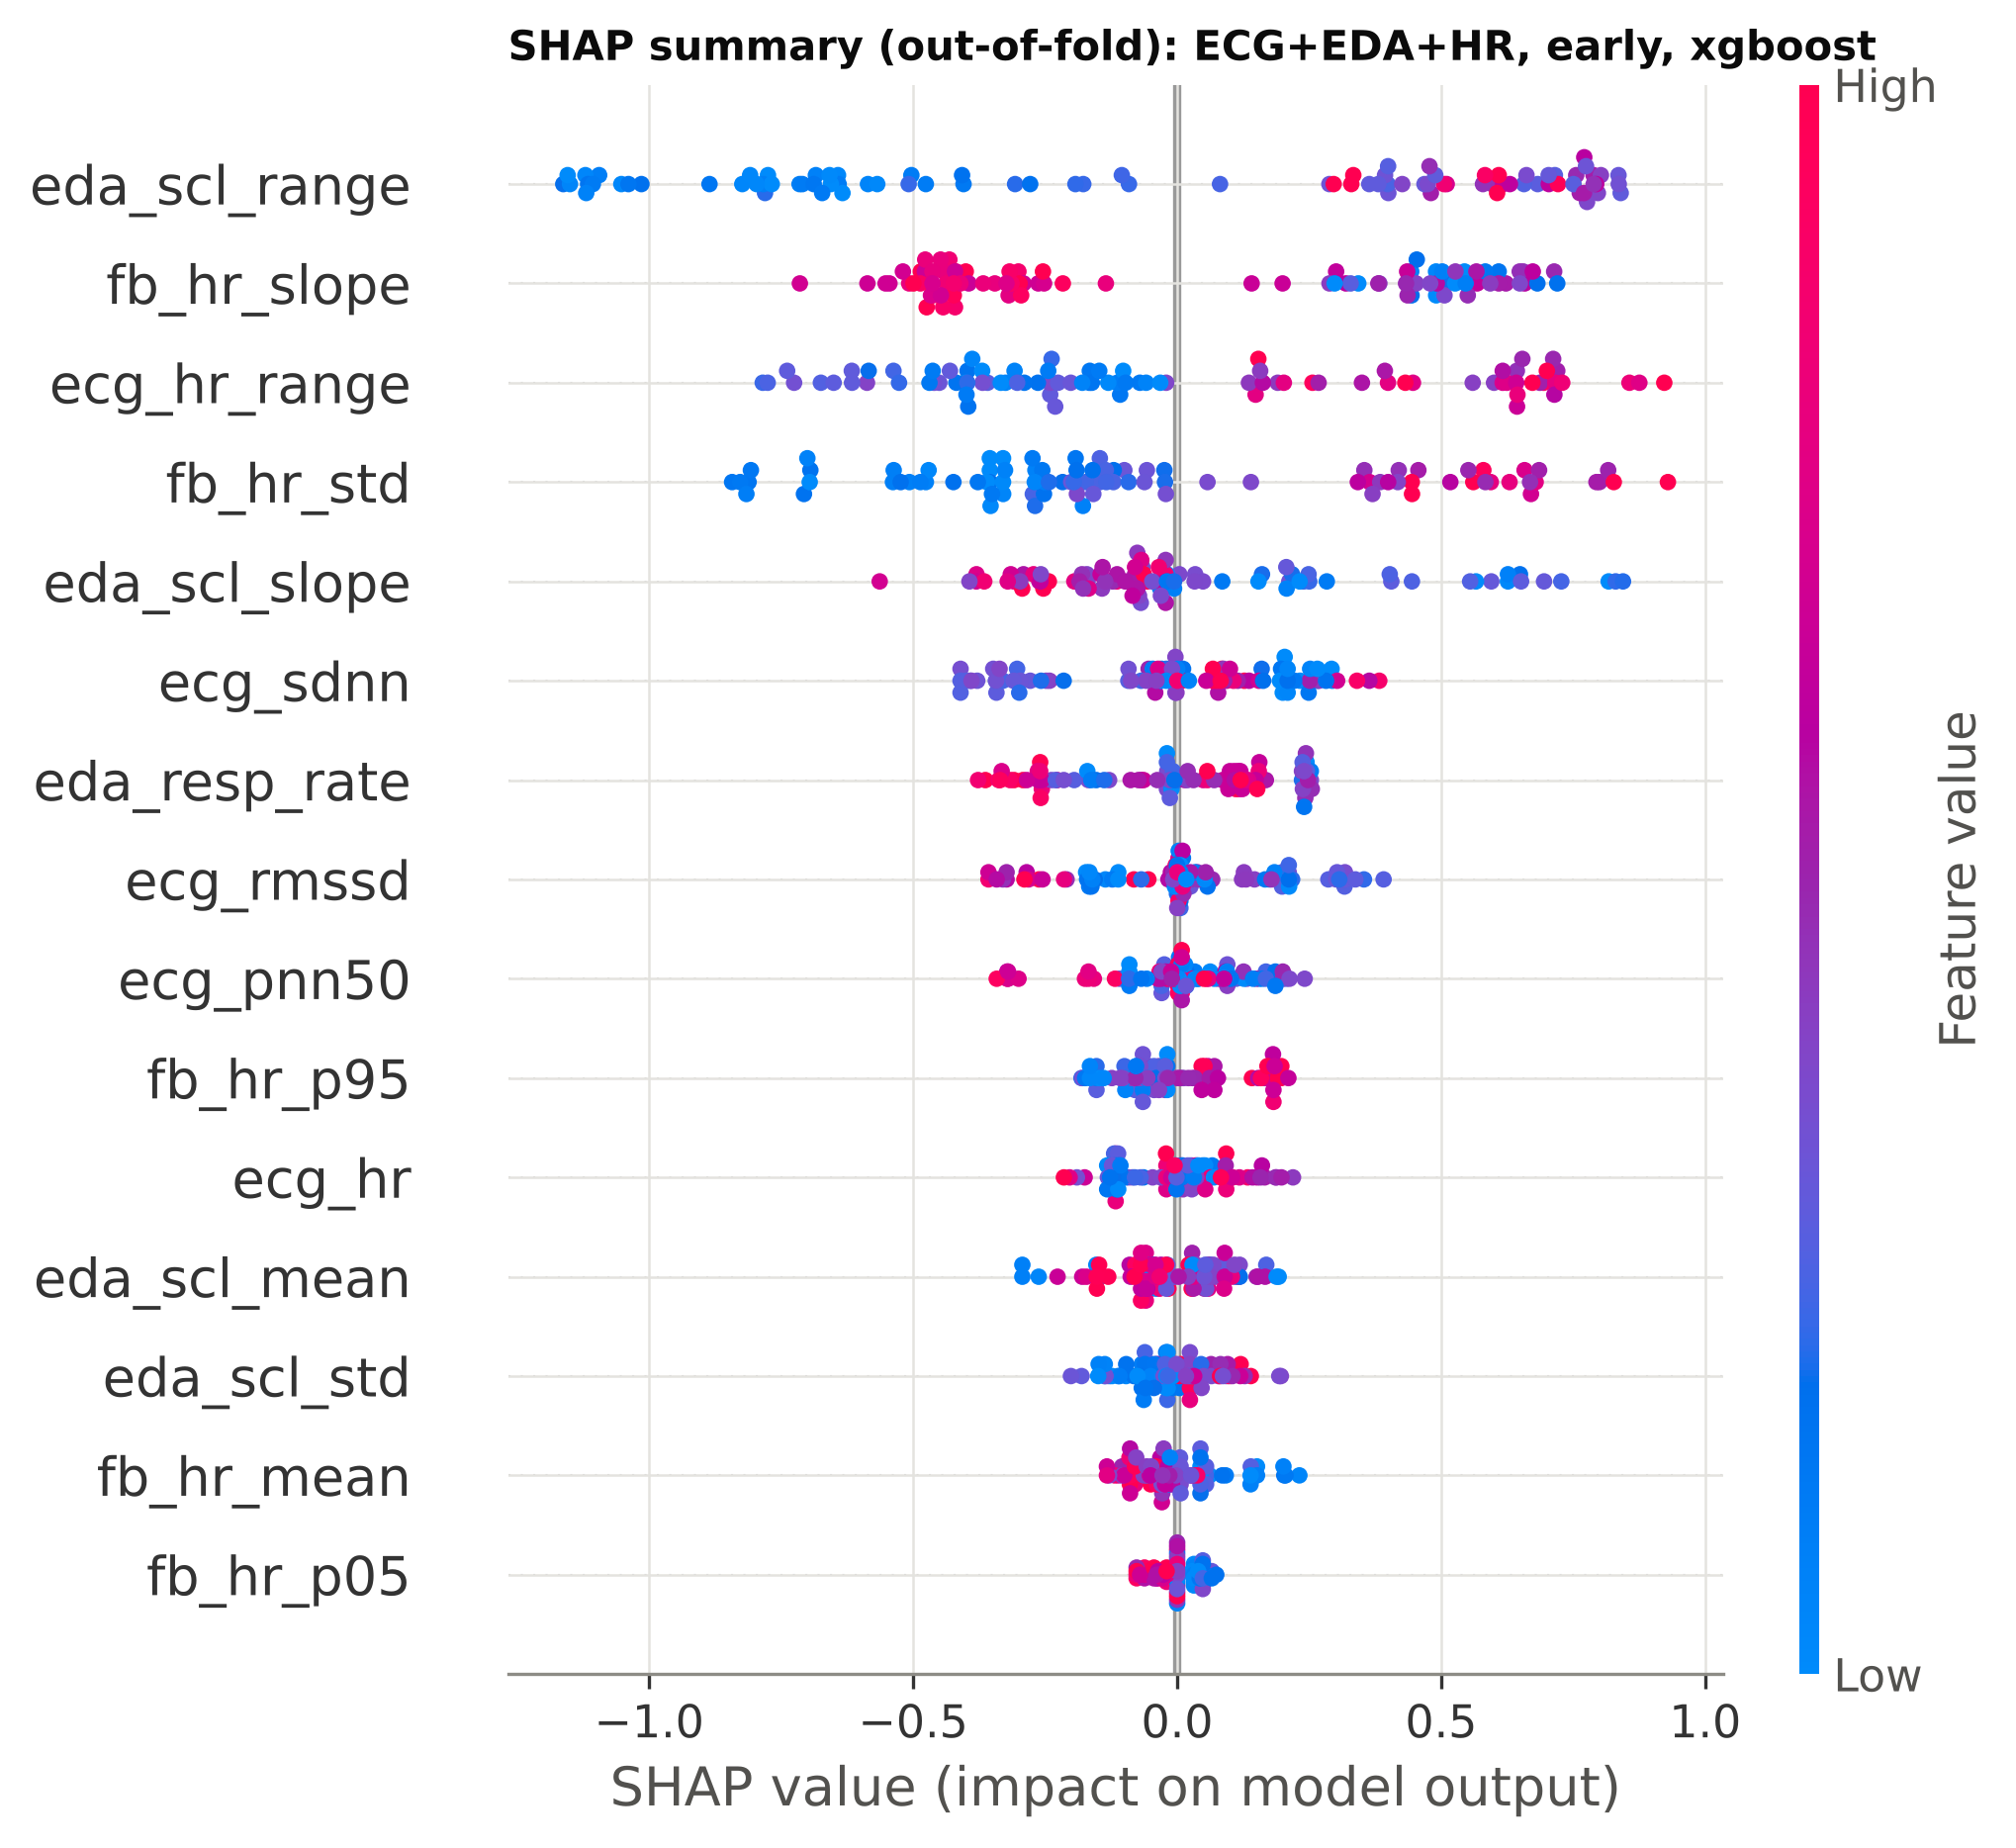

In [3]:
for p in sorted(F.glob('shap_beeswarm_*.png'))[:2]: display(Image(p, width=620))

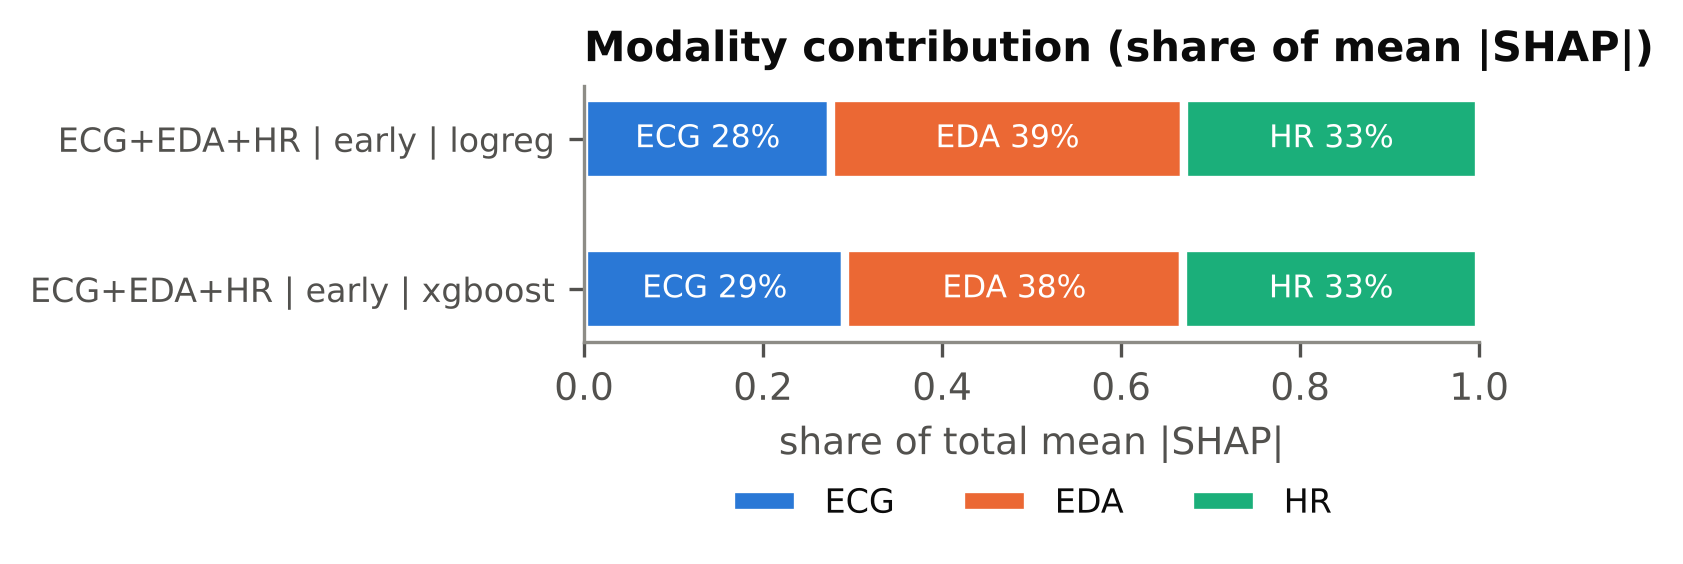

In [4]:
display(Image(F/'shap_modality_share.png', width=520))

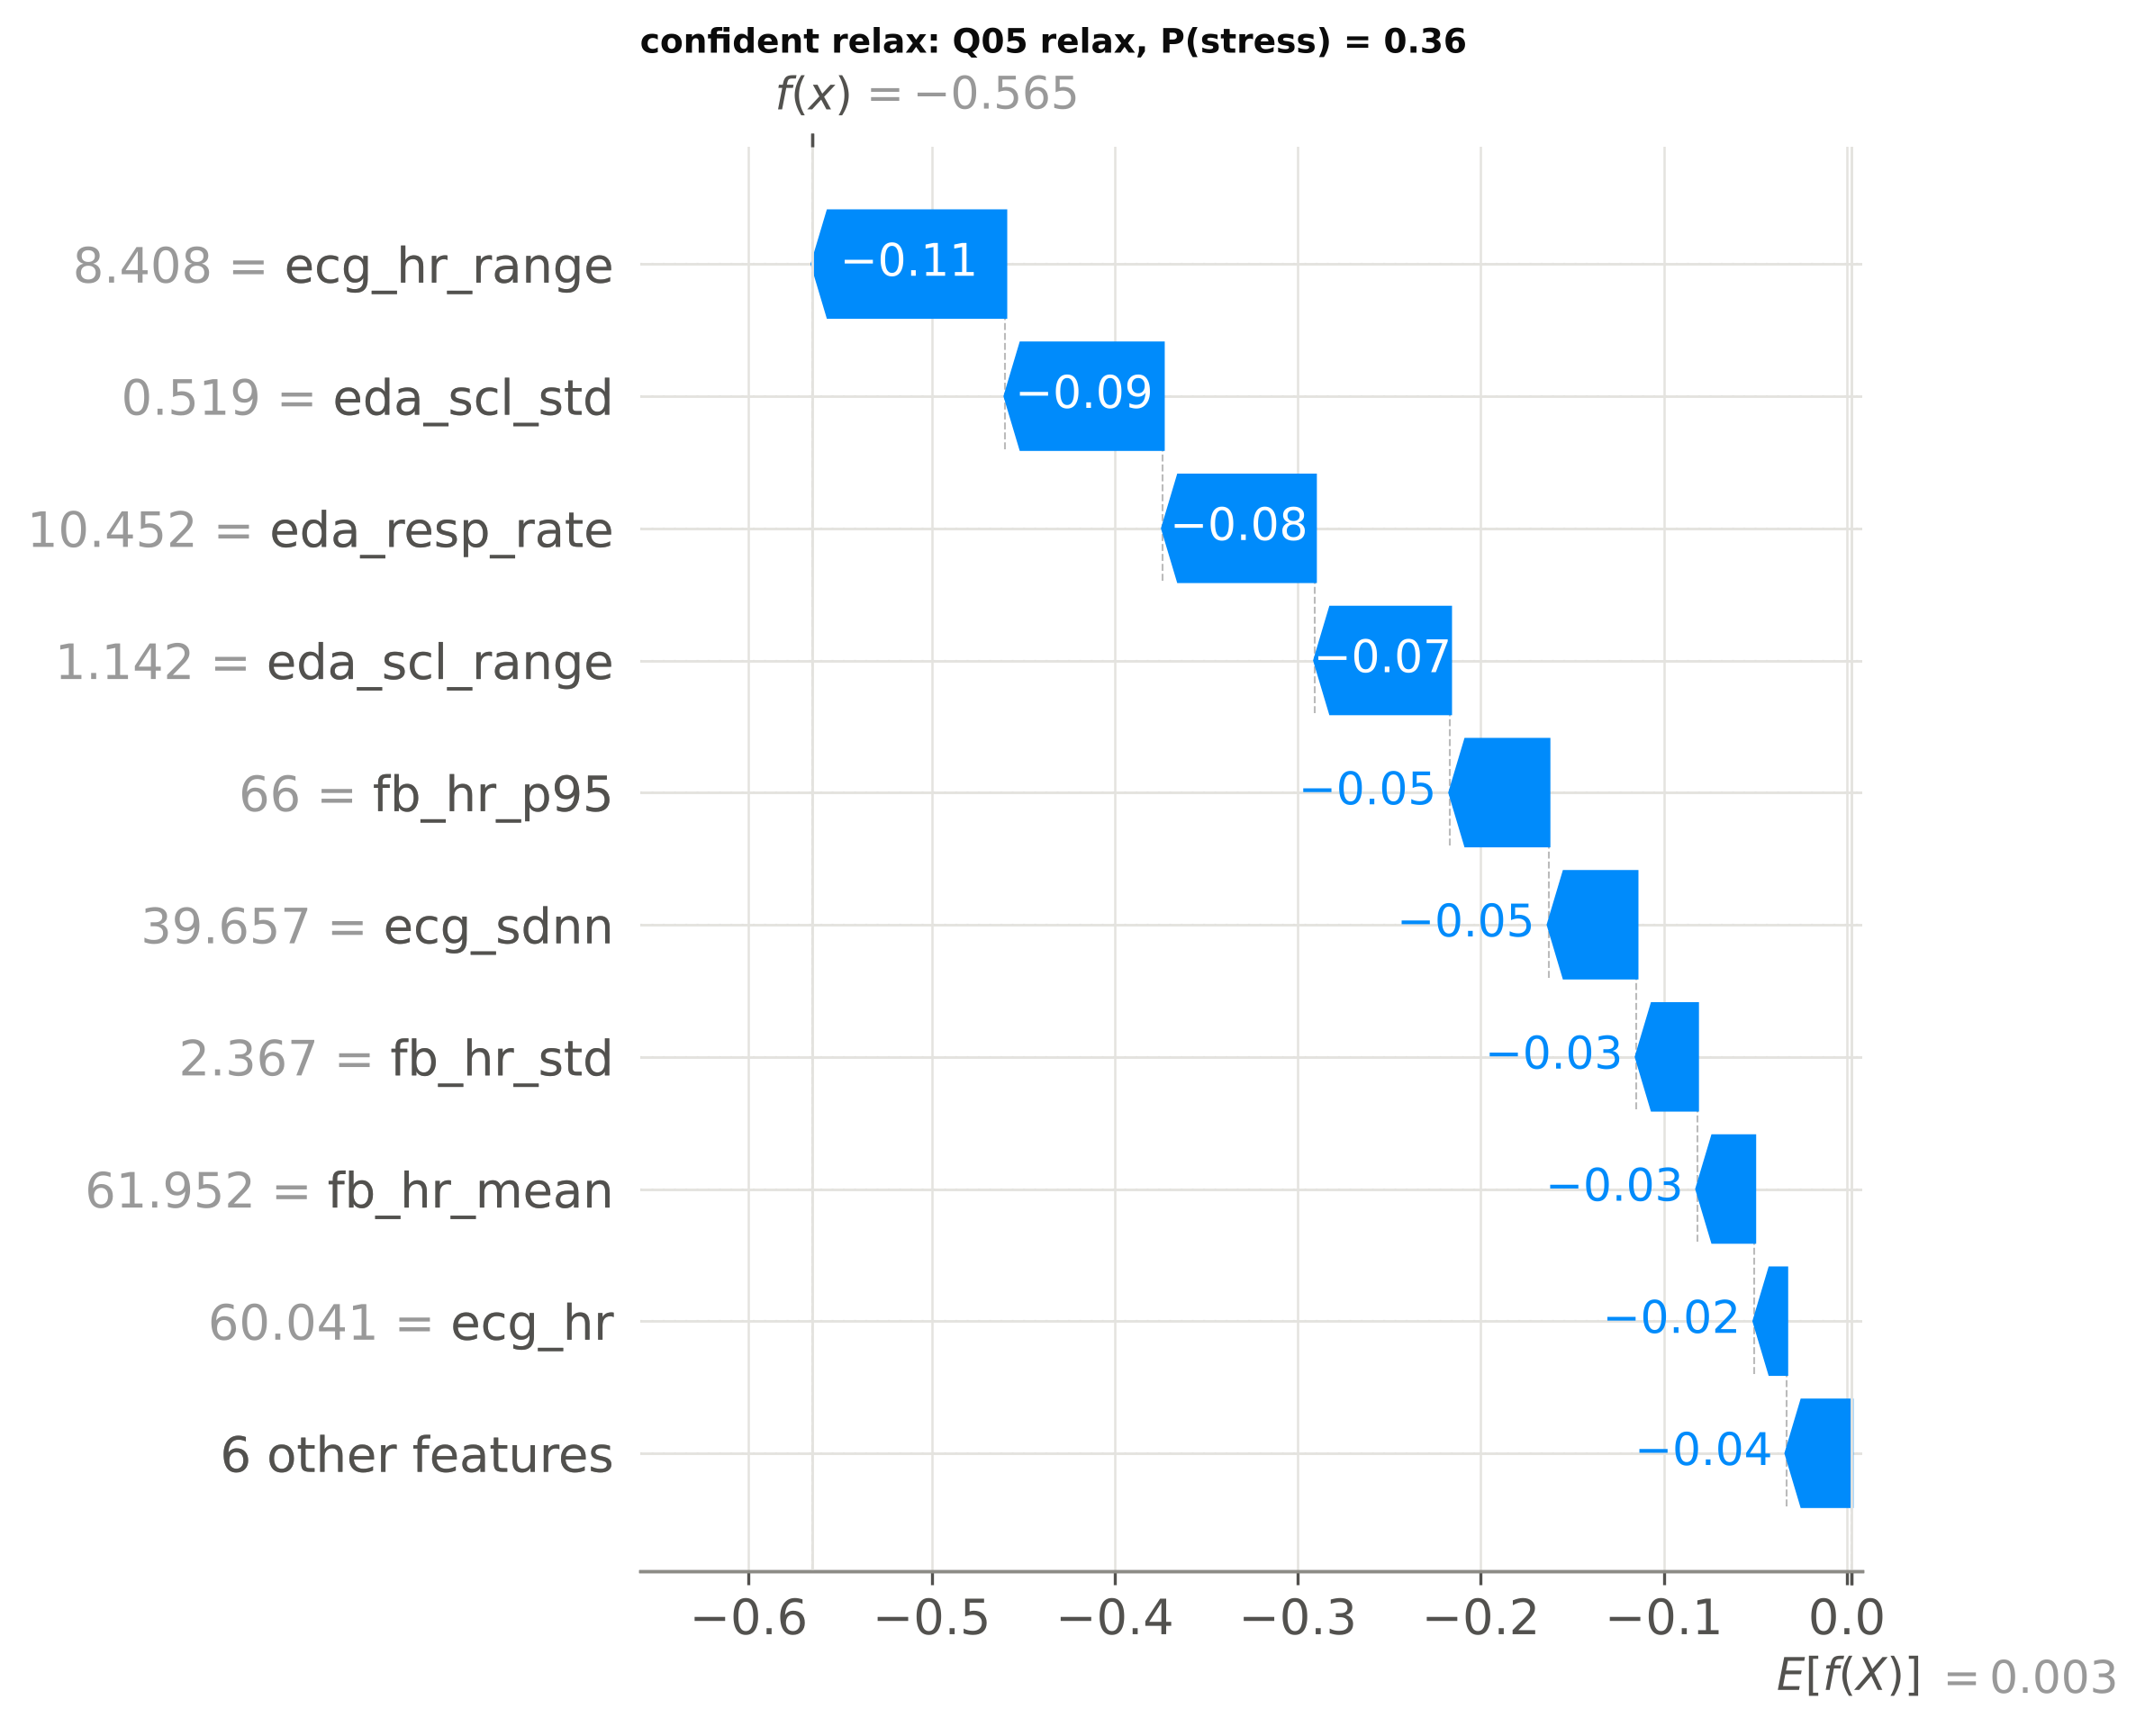

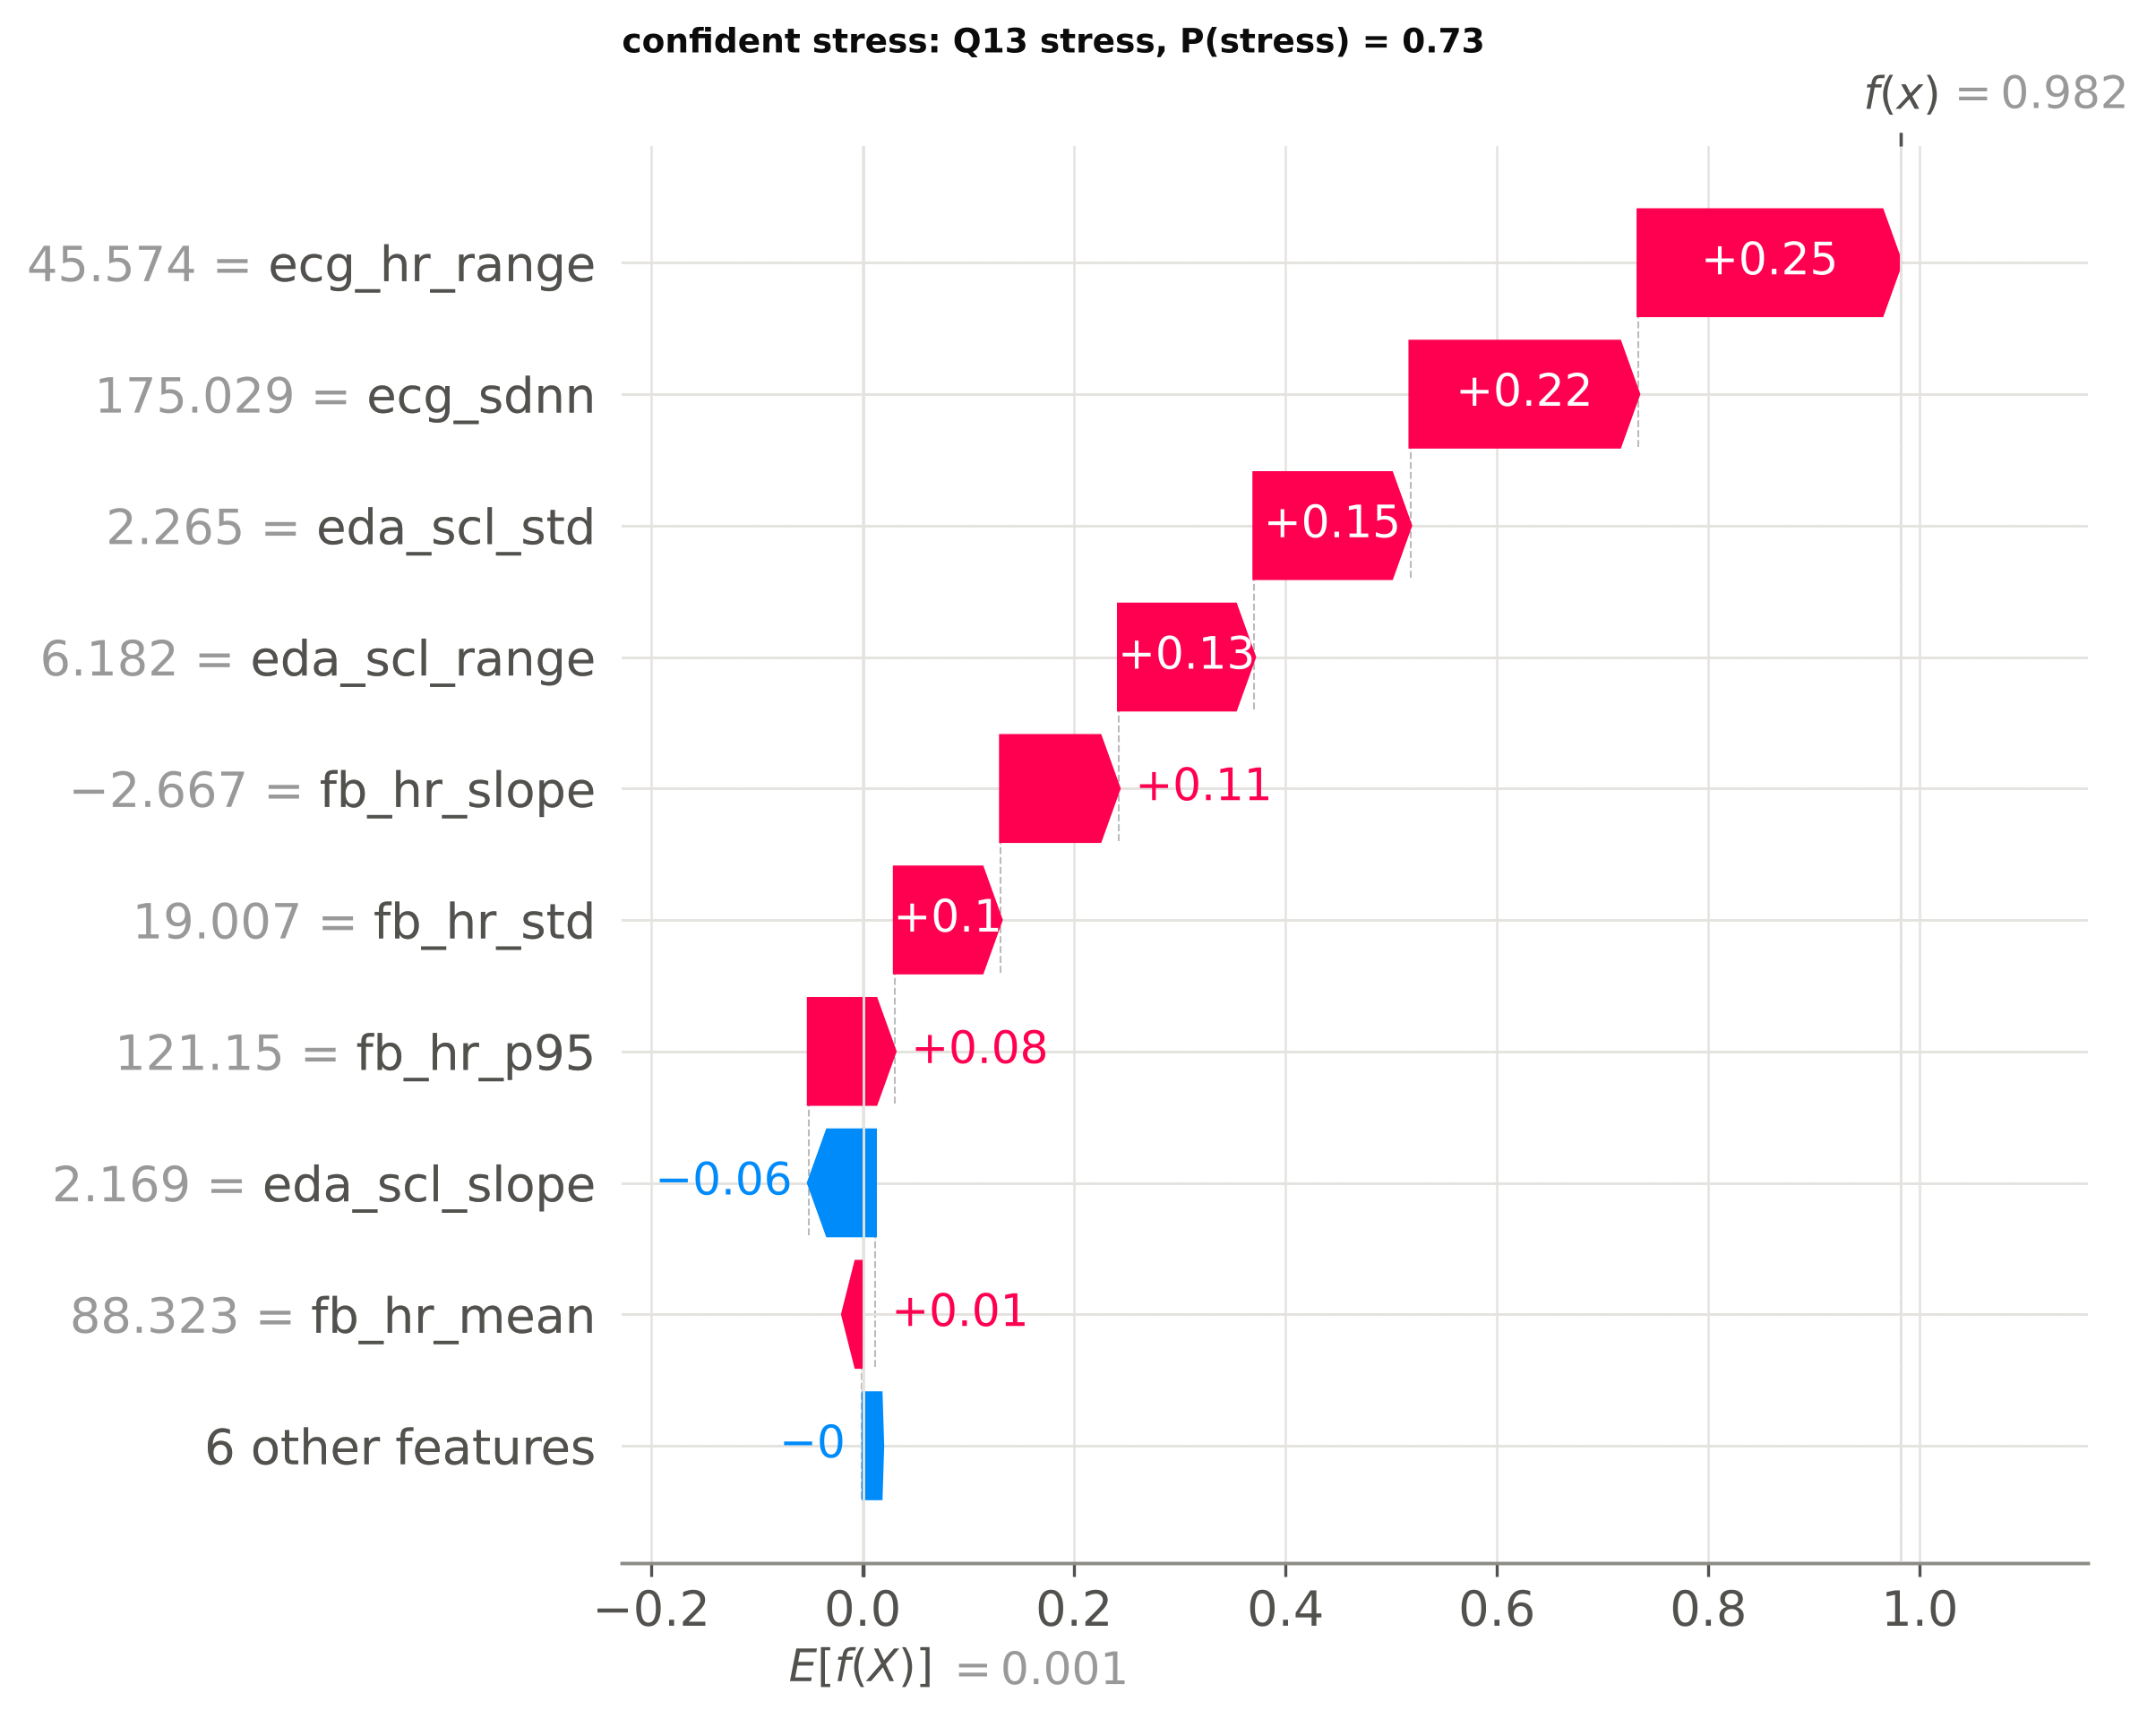

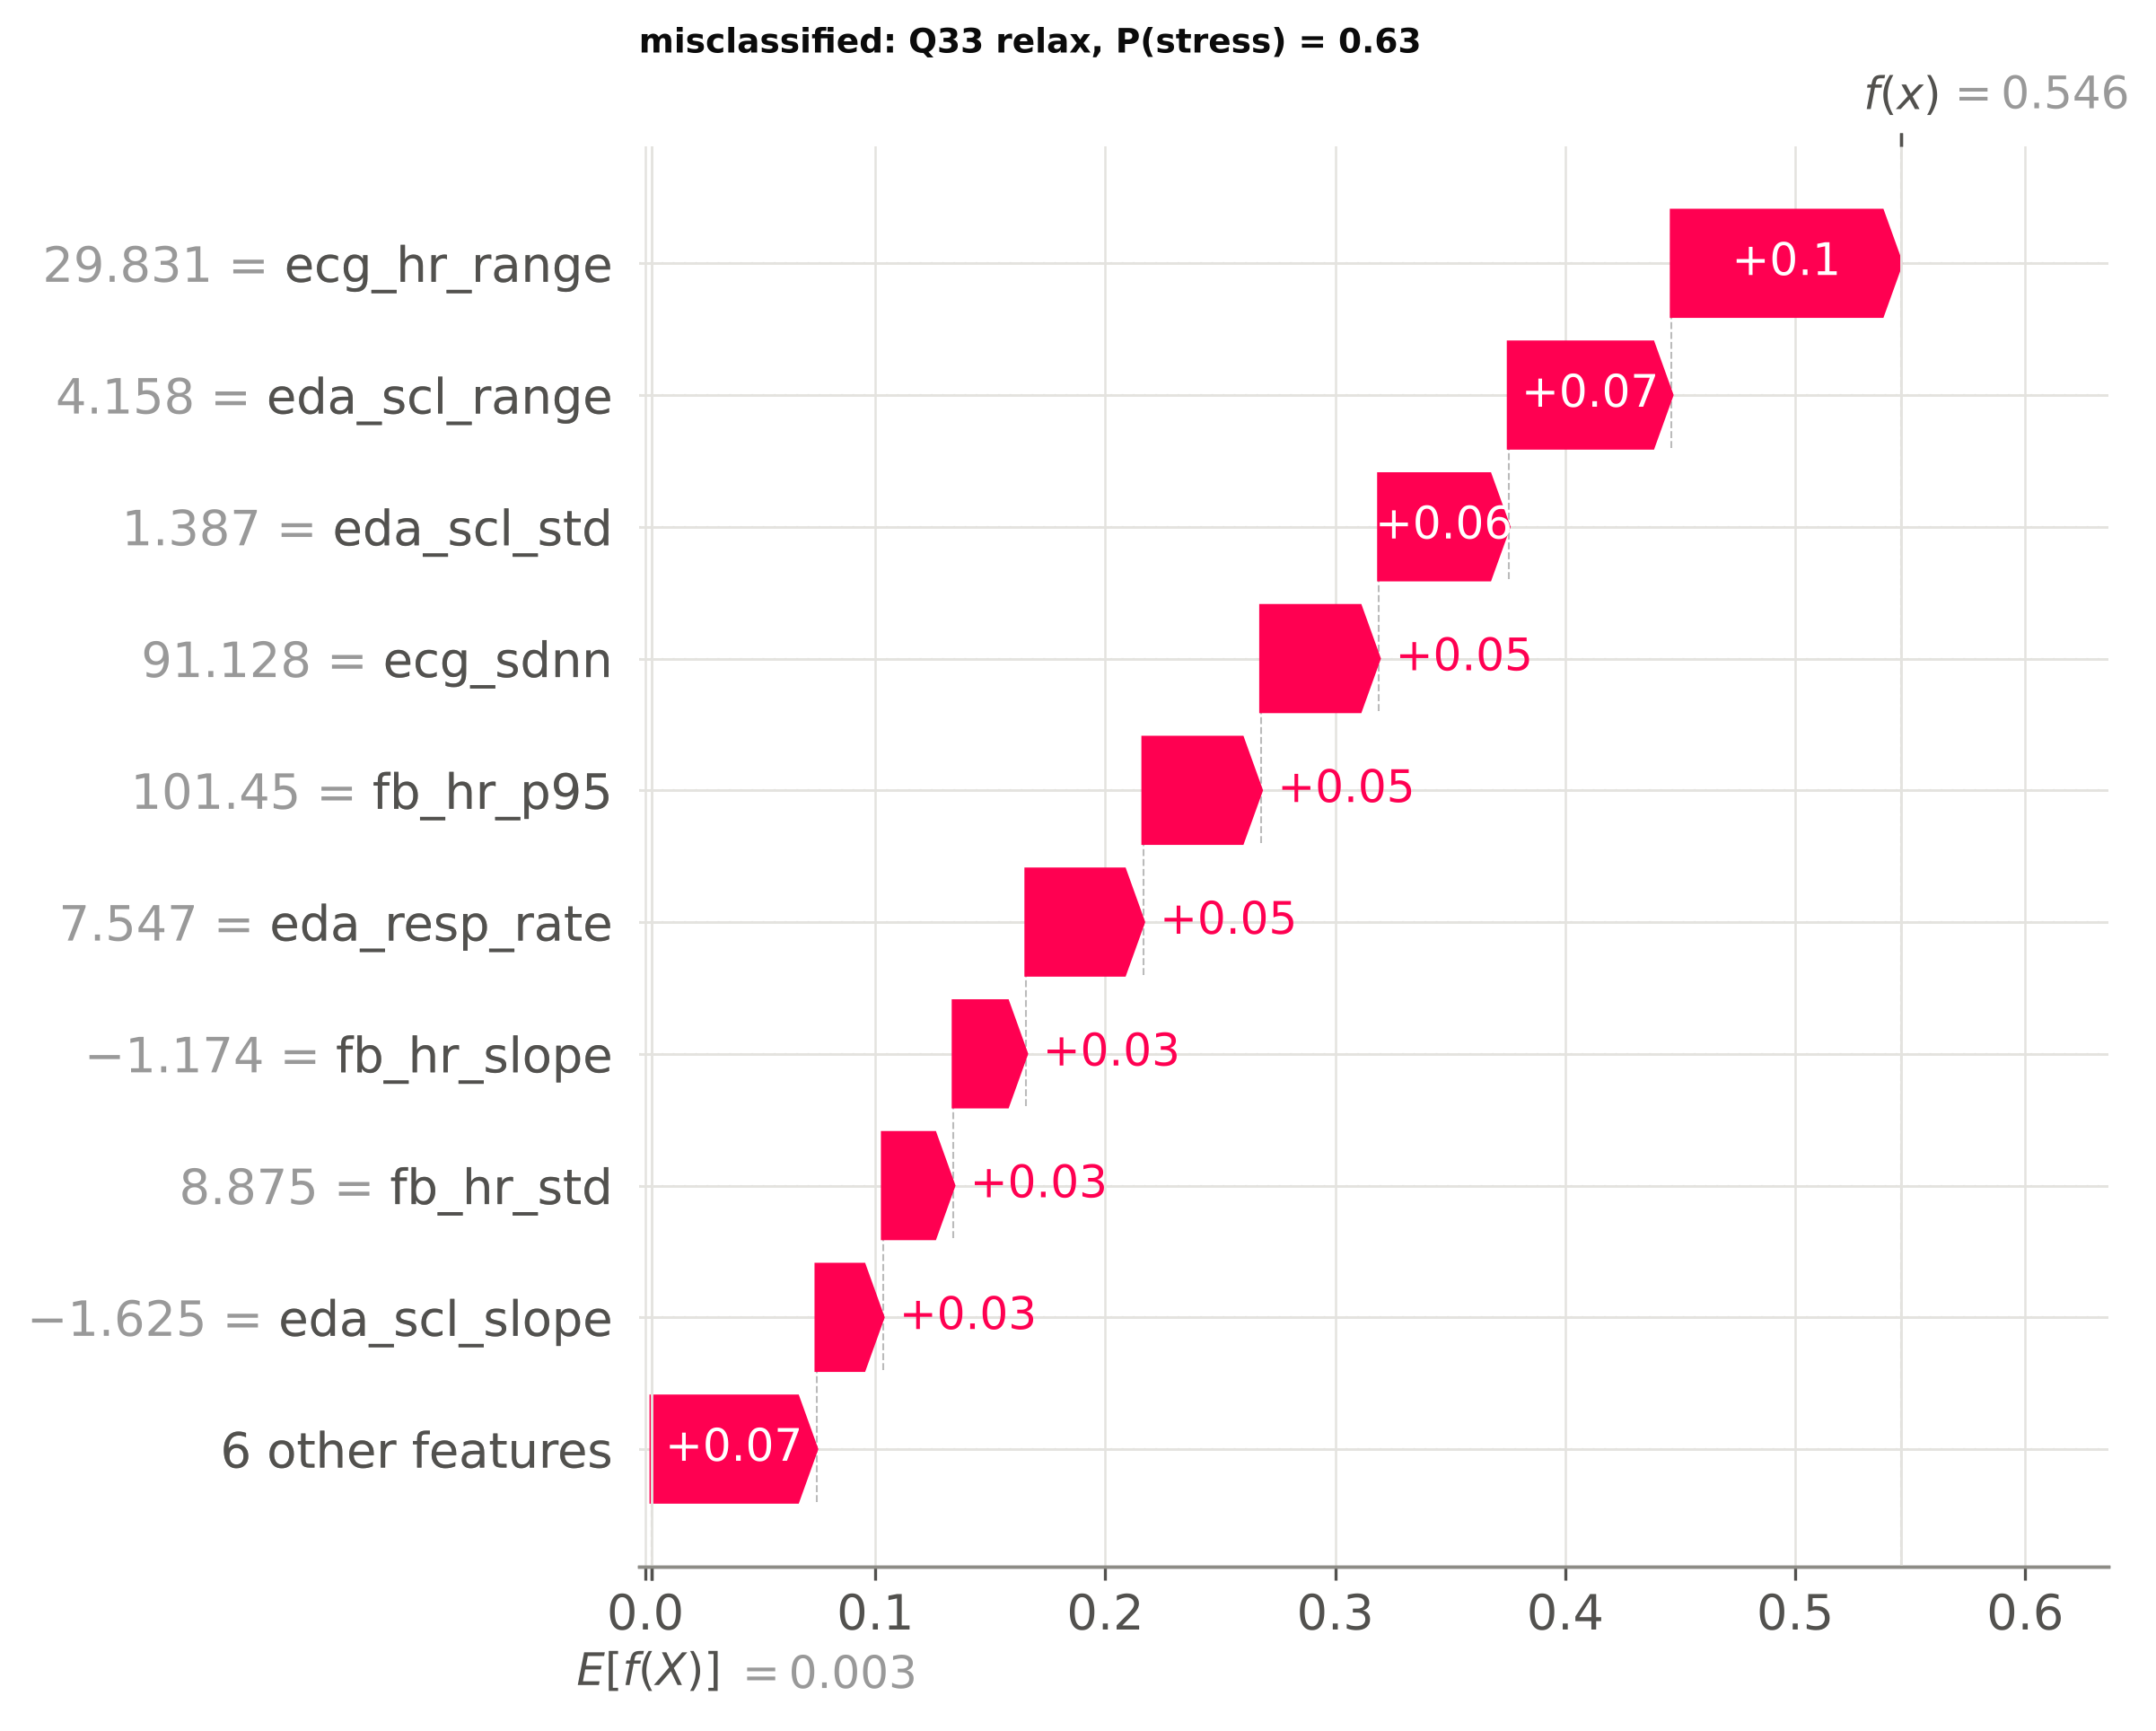

In [5]:
for p in sorted(F.glob('shap_waterfall_*.png')): display(Image(p, width=520))

## Cross-dataset: common indicators

,dataset,contrast,metric,n_pairs,median_change,frac_increase,wilcoxon_p,direction
0,MMASH,asleep - awake,hr,21,-21.8523,0.0000,0.0000,decrease
1,MMASH,asleep - awake,ln_rmssd,21,0.3785,0.9048,0.0000,increase
2,MMASH,asleep - awake,sdnn,21,-4.7827,0.3810,0.8917,decrease
3,QoL_Stress,stress - relax,hr,51,0.7240,0.5294,0.7287,increase
4,QoL_Stress,stress - relax,ln_rmssd,51,0.0699,0.5490,0.5486,increase
5,QoL_Stress,stress - relax,sdnn,51,9.7109,0.5686,0.0206,increase


,dataset,indicator,measure,n,rho,p_value,ci_low,ci_high,p_fdr
0,MMASH,hr (awake),STAI state,21,-0.013,0.955,-0.426,0.416,0.955
1,MMASH,ln_rmssd (awake),STAI state,21,0.223,0.331,-0.263,0.620,0.927
2,MMASH,hr (awake),STAI trait,20,0.047,0.845,-0.432,0.497,0.955
3,MMASH,ln_rmssd (awake),STAI trait,20,0.274,0.242,-0.168,0.683,0.927
4,MMASH,hr (awake),Daily Stress Inventory,21,0.023,0.922,-0.446,0.482,0.955
5,MMASH,ln_rmssd (awake),Daily Stress Inventory,21,-0.329,0.145,-0.716,0.175,0.927
6,MMASH,hr (awake),sleep efficiency,21,-0.087,0.708,-0.458,0.314,0.955
7,MMASH,ln_rmssd (awake),sleep efficiency,21,0.274,0.229,-0.270,0.675,0.927
8,QoL_Stress,hr (relax),STAI (relax),60,-0.031,0.816,-0.329,0.269,0.955
9,QoL_Stress,hr (relax),PSS-14,60,0.027,0.835,-0.236,0.294,0.955


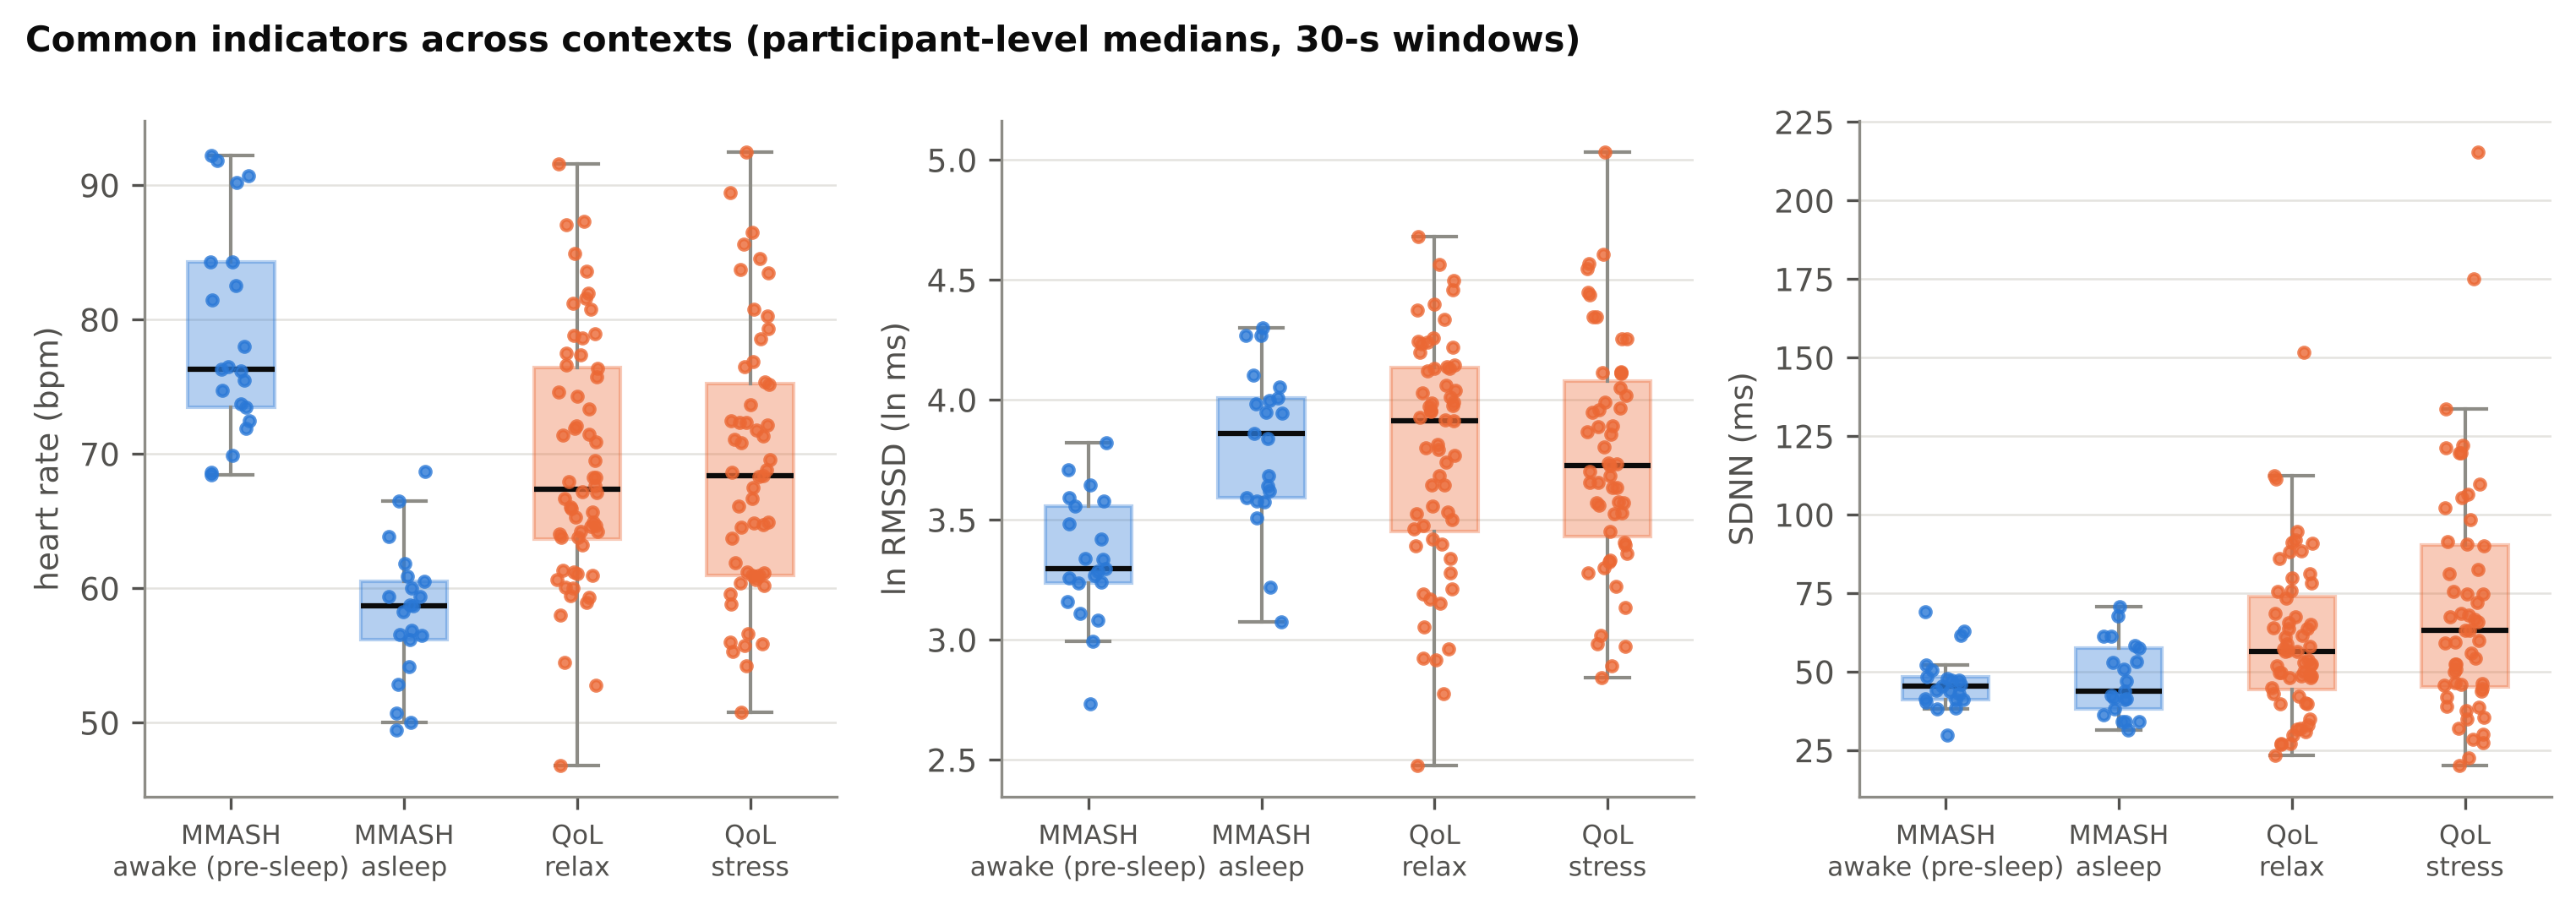

In [6]:
display(pd.read_csv(M/'cross_dataset_state_effects.csv').round(4))
display(pd.read_csv(M/'cross_dataset_associations.csv').round(3))
display(Image(F/'cross_dataset_indicators.png', width=750))